# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: EL SIGMA MAYOR

# Integrantes
* Katerina Lichtensztenin
* Lucia Murillo
* Manel Montalat
* Sofia Cácharo Hernáez

### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

Calcular un nuevo set de parámetros para 

b) $\alpha_u = \alpha_v$ 

c) $K_{12}=0$



In [15]:
import numpy as np
import os

carpeta = os.path.join("calib", "3d")
coord_pix_fotos = np.loadtxt(os.path.join(carpeta, "detected_corners.txt"))
coord_reales_puntos = np.loadtxt(os.path.join(carpeta, "p_W_corners.txt"), delimiter=",")

from funciones_tp import obtenerQ3d, resolverDLT3D, devolverMatricesCalibracion3d

Q = obtenerQ3d(coord_pix_fotos[0],coord_reales_puntos)
print(f"Q = {Q}")

M = resolverDLT3D(Q)
print(f"\nM = {M}")
# el signo de m depende del vector aleatorio que se genera en metpot2k, dentro de diagRH, eso afecta el signo de M y luego su determinante --> impacta en determinante de R 

R, t, K = devolverMatricesCalibracion3d(M)
print(f"\nR: {R}")
Rt = np.zeros((3,4))
Rt[:, :3] = R
Rt[:, 3] = t
print(f"\nLa matriz [R t] es {Rt}")
print(f"con R = {R}")
print(f"y t = {t}")

Q = [[ 0.0000000e+00  8.0000000e+00  0.0000000e+00  1.0000000e+00
   0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
  -0.0000000e+00 -1.4920000e+03 -0.0000000e+00 -1.8650000e+02]
 [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
   0.0000000e+00  8.0000000e+00  0.0000000e+00  1.0000000e+00
  -0.0000000e+00 -1.5000000e+03 -0.0000000e+00 -1.8750000e+02]
 [ 1.0400000e+01  8.0000000e+00  0.0000000e+00  1.0000000e+00
   0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
  -2.7508000e+03 -2.1160000e+03 -0.0000000e+00 -2.6450000e+02]
 [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
   1.0400000e+01  8.0000000e+00  0.0000000e+00  1.0000000e+00
  -1.7316000e+03 -1.3320000e+03 -0.0000000e+00 -1.6650000e+02]
 [ 0.0000000e+00  2.1500000e+01  0.0000000e+00  1.0000000e+00
   0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
  -0.0000000e+00 -4.6977500e+03 -0.0000000e+00 -2.1850000e+02]
 [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00

### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

In [18]:
## PROBLEMA: A VECES A TIENE FILAS NAN Y FALLA

carpeta = os.path.join("calib", "coplanar")
coord_pix_ajedrez = np.loadtxt(os.path.join(carpeta, "img_pts.txt"))
coord_reales_ajedrez = np.loadtxt(os.path.join(carpeta, "obj_pts.txt"))

from funciones_tp import armar_Hs, armarA, calcularMatrizK2D, obtenerPose2D

# Armamos la lista de Homografias a partir de los puntos de los tableros
Hlst_ajedrez = armar_Hs(coord_pix_ajedrez, coord_reales_ajedrez)
A = armarA(Hlst_ajedrez)
print(f"\nLa matriz A es {A}")
K_ajedrez = calcularMatrizK2D(A) 
Rj, tj = obtenerPose2D(Hlst_ajedrez[0], K_ajedrez)

print(f"\nLa matriz de calibracion K es {K_ajedrez}")
print(f"\nLa matriz de rotacion R es {Rj}")
print(f"\nEl vector de traslacion t es {tj}")


La matriz A es [[-3.69128685e-02  1.88838133e+00  4.33067224e-02 -2.22834905e-05
   6.84763191e-05 -7.64164382e-10]
 [ 1.90253308e+00  1.60538126e-01 -1.87430919e+00  1.38123939e-04
   4.47487119e-05  2.30525909e-09]
 [ 4.13404619e-01  1.71536341e+00 -3.93002138e-01  1.54161198e-05
   7.43595625e-05 -6.29321846e-11]
 [ 1.72232100e+00 -1.61259449e+00 -1.70829479e+00  1.49655992e-04
  -2.93751065e-05  3.05257056e-09]
 [ 1.16247348e-01  1.99136873e+00 -8.43184279e-02  1.22413223e-05
   1.05594407e-04  3.22249253e-10]
 [ 2.01195178e+00 -4.00444920e-01 -1.97055794e+00  2.13374270e-04
  -2.10621424e-05  5.65726146e-09]
 [ 1.01441490e-01  2.07227432e+00 -7.30295416e-03  1.42947626e-04
   1.04617003e-04  6.98797855e-09]
 [ 2.05196676e+00 -2.18923320e-01 -2.08838777e+00  1.95024813e-04
  -2.78440724e-04 -3.94249593e-09]
 [-1.68259891e-01  2.01795746e+00  1.90927949e-01 -6.91506501e-05
   1.87598380e-04 -5.03955758e-09]
 [ 2.10536631e+00  7.20833855e-01 -1.93351343e+00  3.92830329e-04
   1.3983

### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$. 
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

In [ ]:
from funciones_tp import estimar_H, inversa, multiplicarAx
puntos_pixeles = np.loadtxt("puntos_gol_enzo.txt")

imgPts_enzo = np.array(puntos_pixeles, dtype=float).reshape(-1)
objPts_enzo =np.array([(24.84,0),(24.84,5.5),(43.16,0),(43.16,5.5),(34,11),(26.69,16.5),(41.31,16.5),(30.34,0),(37.66,0)])

H_enzo = estimar_H(imgPts_enzo, objPts_enzo)

inversa_H_enzo = inversa(H_enzo)

punto_pie_enzo = np.loadtxt("punto_enzo.txt")
pie_enzo = np.array((punto_pie_enzo[0], punto_pie_enzo[1], 1)) #agrego el 1 para las dimensiones

posicion_pie_en_imagen = multiplicarAx(inversa_H_enzo, pie_enzo) # = (U,V,W)
posicion_pie_en_imagen = posicion_pie_en_imagen/posicion_pie_en_imagen[2] #normalizamos para que la tercera coordenada sea 1
print(f"Posición del pie en la imagen: {posicion_pie_en_imagen}")

distancia_pie_a_arco = posicion_pie_en_imagen[1] #coordenada V 
print(f"La distancia del pie al arco es: {round(distancia_pie_a_arco,4)} metros")

Posición del pie en la imagen: [39.84082698 22.07663812  1.        ]
La distancia del pie al arco es: 22.0766 metros


In [19]:
import cv2
import matplotlib.pyplot as plt
from funciones_tp import circulo
pies_jugadores = np.loadtxt("pies_jugadores_arg.txt")
img = cv2.imread(os.path.join("futbol", "test-gol-enzo.png"))

fig, ax = plt.subplots()
ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)) #para que no sean avatares
for coord_pie_pixel in pies_jugadores:
    coord_pie_pixel = np.array((coord_pie_pixel[0], coord_pie_pixel[1],1)) #agrego el 1 para las dimensiones
    posicion_pie_mundo = multiplicarAx(inversa_H_enzo, coord_pie_pixel) # = (U,V,1)
    posicion_pie_mundo = posicion_pie_mundo/posicion_pie_mundo[2] #normalizamos para que la tercera coordenada sea 1
    U = posicion_pie_mundo[0]
    V = posicion_pie_mundo[1]
    U_c, V_c = circulo((U,V), 1.0, 100)

    u_ci, v_ci = [],[]
    for U_circulo,V_circulo in zip(U_c,V_c): #chequear este zip
        punto_circulo_jugador = multiplicarAx(H_enzo,np.array([U_circulo,V_circulo,1]))
        u_ci.append(punto_circulo_jugador[0]/punto_circulo_jugador[2])
        v_ci.append(punto_circulo_jugador[1]/punto_circulo_jugador[2])
        ax.plot(u_ci,v_ci,color="white", linewidth=2)
        #ax.fill(u_ci, v_ci, facecolor=(1, 1, 1, 0.3), edgecolor="none", opacity=.3)   # relleno pero NO traslúcido, si lo permiten y lo piden, ver si existe polygon
plt.show()

ModuleNotFoundError: No module named 'cv2'

Posición del defensor en la imagen: [90.62826276 16.68612626  1.        ]


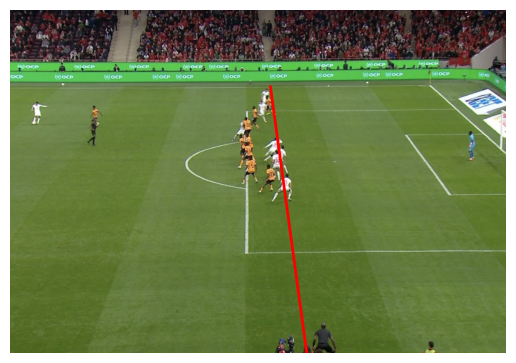

In [ ]:
from funciones_tp import estimar_H, inversa, multiplicarAx
#archivo = "puntos_offside.txt"
puntos_pixeles_offside = np.loadtxt("puntos_offside.txt")
#puntos_pixeles_offside = [(736, 317), (732, 559), (734, 757), (1304, 235), (1230, 390), (1365, 578), (1010, 473)]
imgPts_offside = np.array(puntos_pixeles_offside, dtype=float).reshape(-1)
objPts_offside =np.array([(88.5,13.84),(88.5,41.31),(88.5,54.16),(105,0),(99.5,24.84),(99.5,43.16),(94,34)])

H_offside = estimar_H(imgPts_offside, objPts_offside)
inversa_H_off = inversa(H_offside)

posicion_pie_defensor = np.loadtxt("pie_defensor.txt")

pie_defensor = np.array([posicion_pie_defensor[0], posicion_pie_defensor[1], 1]) #agrego el 1 para las dimensiones
posicion_defensor_en_imagen = multiplicarAx(inversa_H_off, pie_defensor) # = (U,V,W)
posicion_defensor_en_imagen = posicion_defensor_en_imagen/posicion_defensor_en_imagen[2] #normalizamos para que la tercera coordenada sea 1, (U,V,1)

print(f"Posición del defensor en la imagen: {posicion_defensor_en_imagen}")

distancia_defensor_a_arco = posicion_defensor_en_imagen[0] #coordenada V 

#definimos dos puntos para trazar la recta en la imagen
P1_estadio = (posicion_defensor_en_imagen[0],0)
P2_estadio = (posicion_defensor_en_imagen[0],68)
p1_imagen = multiplicarAx(H_offside,np.array([P1_estadio[0],P1_estadio[1],1]))
p1_imagen = p1_imagen / p1_imagen[2]
p2_imagen = multiplicarAx(H_offside,np.array([P2_estadio[0],P2_estadio[1],1]))
p2_imagen = p2_imagen / p2_imagen[2]

#graficamos
img_off = cv2.imread(os.path.join("futbol", "test-fuera-de-juego.png"))
alto, ancho, _ = img_off.shape
fig, ax = plt.subplots()
ax.imshow(cv2.cvtColor(img_off, cv2.COLOR_BGR2RGB)) #para que no sean avatares
ax.plot([p1_imagen[0], p2_imagen[0]], [p1_imagen[1], p2_imagen[1]], color="red", linewidth=2)   

ax.axis("off") # sacamos los ejes y números

ax.set_xlim(0, ancho) # sacamos la franja blanca
ax.set_ylim(alto, 0)  # Invertido para mantener el origen arriba a la izquierda

plt.show()

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

---